In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Select place names based on source of truth
place_names = pd.read_csv("../name_extraction/entity_names/holinshed_places.csv")
place_names.info()
print(f"Number of unique places: {len(place_names)}")

<class 'pandas.DataFrame'>
RangeIndex: 956 entries, 0 to 955
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               956 non-null    str    
 1   type               956 non-null    str    
 2   confidence         956 non-null    float64
 3   n_entries          956 non-null    int64  
 4   spelling_variants  956 non-null    str    
 5   example_entry      956 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 44.9 KB
Number of unique places: 956


In [2]:
# Define confidence categories
confidence_bins = [0, 0.25, 0.50, 0.75, 1.00]
confidence_labels = ["low", "medium", "high", "very high"]
print(f"Low confidence bin: [{confidence_bins[0]},{confidence_bins[1]})", flush=True)
print(f"Medium confidence bin: [{confidence_bins[1]},{confidence_bins[2]})", flush=True)
print(f"High confidence bin: [{confidence_bins[2]},{confidence_bins[3]})", flush=True)
print(f"Very high confidence bin: [{confidence_bins[3]},{confidence_bins[4]})", flush=True)

# Categorize places in confidence categories based on pre-defined confidence bins
place_names["confidence_category"] = pd.cut(
    place_names["confidence"],
    bins=confidence_bins,
    labels=confidence_labels,
    include_lowest=True,
    right=False
)

# Count names in each confidence category
confidence_counts = (
    place_names["confidence_category"]
    .value_counts()
    .sort_index()
    .rename_axis("confidence_level")
    .reset_index(name="count")
)

display(confidence_counts)


veryhigh_conf_places = place_names.loc[place_names["confidence"].ge(confidence_bins[3])].copy()
print(
    f"We will work with the {len(veryhigh_conf_places)} very high confidence places, or {(len(veryhigh_conf_places) / len(place_names))*100:.2f}% of all places."
)

Low confidence bin: [0,0.25)
Medium confidence bin: [0.25,0.5)
High confidence bin: [0.5,0.75)
Very high confidence bin: [0.75,1.0)


,confidence_level,count
0,low,0
1,medium,6
2,high,87
3,very high,863


We will work with the 863 very high confidence places, or 90.27% of all places.


In [4]:
import re
import xml.etree.ElementTree as ET
from pathlib import Path

import pandas as pd

# Locate the repository root
repo_root = Path.cwd().resolve()
if not (repo_root / "1577_files").is_dir():
    repo_root = repo_root.parent

xml_path = repo_root / "1577_files" / "monarchs_reign.xml"
if not xml_path.is_file():
    raise FileNotFoundError(f"File not found: {xml_path}")

# Parse the TEI XML
TEI = "{http://www.tei-c.org/ns/1.0}"
root = ET.parse(xml_path).getroot()

def normalize(text):
    """Normalize whitespace, case, and historical long-s."""
    return re.sub(r"\s+", " ", text).strip().casefold().replace("ſ", "s")

# Extract text for each regnal entry
reigns = []

for entry in root.iter(TEI + "div"):
    if entry.get("type") != "regnal_entry":
        continue

    text = normalize(" ".join(entry.itertext()))

    reigns.append(
        {
            "ruler": entry.get("n"),
            "text": text,
            "word_count": len(text.split()),
        }
    )

if not reigns:
    raise ValueError(f"No regnal entries found in {xml_path}")

ruler_order = [reign["ruler"] for reign in reigns]
places = veryhigh_conf_places.copy()

print(f"Searching {len(places)} places across {len(reigns)} regnal entries.")


# Compile one regex per place, including its spelling variants
place_patterns = {}

for _, place in places.iterrows():
    search_keys = [str(place["name"])]

    if pd.notna(place["spelling_variants"]):
        search_keys.extend(str(place["spelling_variants"]).split("|"))

    search_keys = {normalize(key) for key in search_keys if key.strip()}

    alternatives = "|".join(
        re.escape(key) for key in sorted(search_keys, key=len, reverse=True)
    )

    place_patterns[place["name"]] = re.compile(rf"(?<!\w)(?:{alternatives})(?!\w)")


# Count place mentions in each reign
results = []

for reign in reigns:
    print(f"Processing reign: {reign['ruler']}...")
    for place_name, pattern in place_patterns.items():
        results.append(
            {
                "file": reign["ruler"],
                "place_name": place_name,
                "xml_count": len(pattern.findall(reign["text"])),
                "word_count": reign["word_count"],
            }
        )

print("Finished processing.")

results = pd.DataFrame(results)


# Create place-by-reign count matrix in XML order
place_counts_by_reign = (
    results.pivot_table(
        index="place_name",
        columns="file",
        values="xml_count",
        aggfunc="sum",
        fill_value=0,
    )
    .reindex(columns=ruler_order)
    .astype(int)
)

place_counts_by_reign.info()

Searching 863 places across 23 regnal entries.
Processing reign: WilliamConqueror...
Processing reign: WilliamRufus...
Processing reign: HenryFirst...
Processing reign: Stephen...
Processing reign: Henry II...
Processing reign: Richard I...
Processing reign: John...
Processing reign: Henry III...
Processing reign: Edward I...
Processing reign: EdwardII...
Processing reign: Edward III...
Processing reign: Richard II...
Processing reign: Henry IV...
Processing reign: Henry V...
Processing reign: Henry VI...
Processing reign: Edward IV...
Processing reign: Edward V...
Processing reign: Richard III...
Processing reign: Henry VII...
Processing reign: Henry VIII...
Processing reign: Edward VI...
Processing reign: Mary...
Processing reign: Elizabeth I...
Finished processing.
<class 'pandas.DataFrame'>
Index: 862 entries, Abbey Church of Batteil to yuell
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   WilliamConque

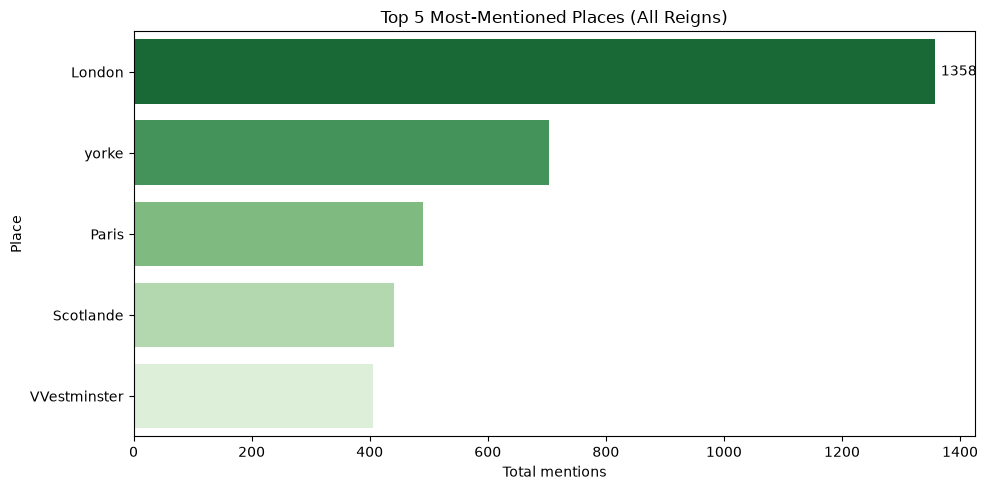

Coverage:


,word_count,places_found,total_mentions
file,,,
WilliamConqueror,18966,36,182
WilliamRufus,16440,31,143
HenryFirst,23814,35,230
Stephen,24496,52,270
Henry II,65156,70,530
Richard I,52290,50,325
John,49892,66,461
Henry III,103081,74,929
Edward I,51715,48,354


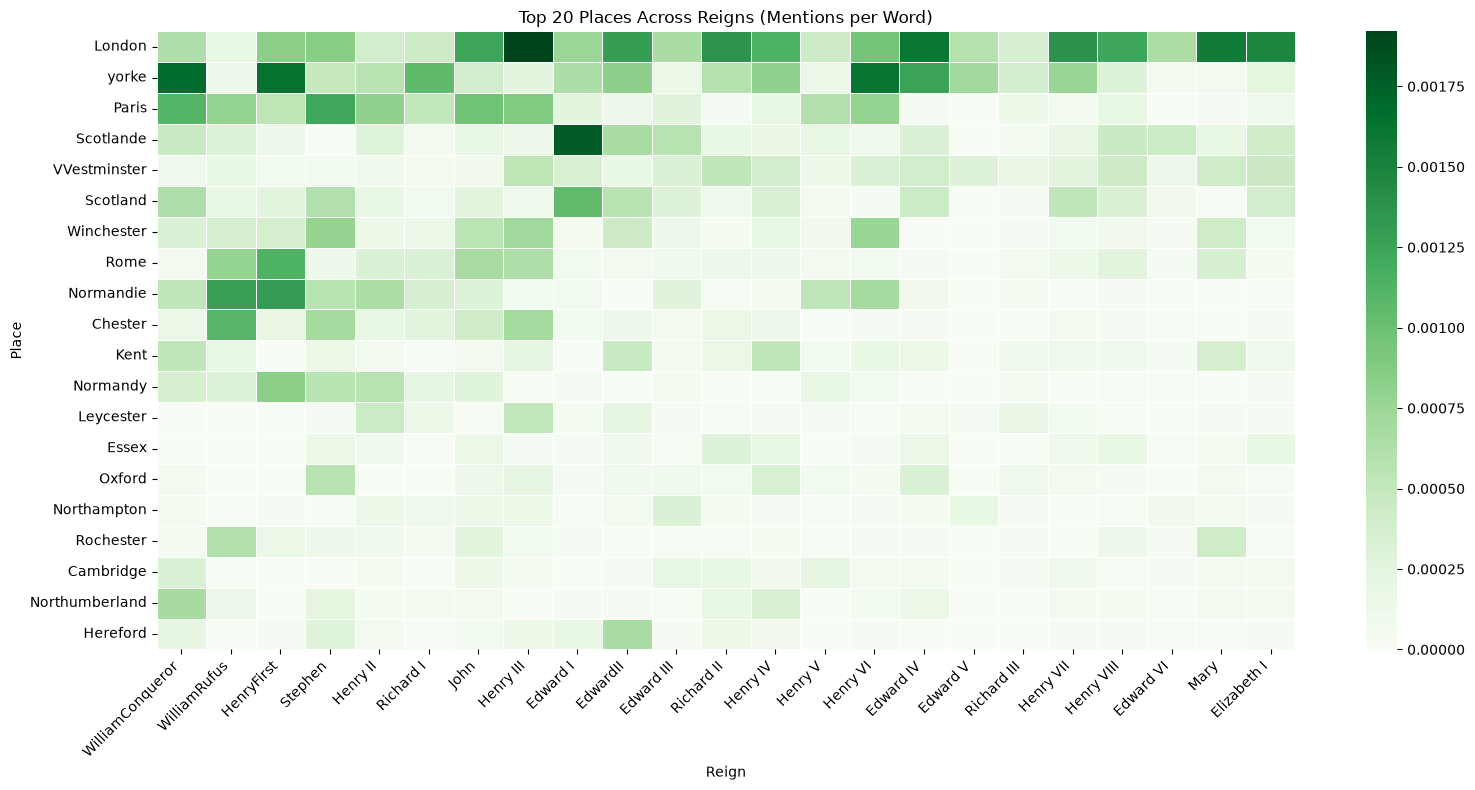

In [10]:
# Top 5 most-mentioned places: bar chart
place_totals = place_counts_by_reign.sum(axis=1).sort_values(ascending=False)
top_5_places = place_totals.head(5)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=top_5_places.values,
    y=top_5_places.index,
    hue=top_5_places.index,
    palette="Greens_r",
    legend=False,
)

ax.bar_label(ax.containers[0], padding=4)
plt.title("Top 5 Most-Mentioned Places (All Reigns)")
plt.xlabel("Total mentions")
plt.ylabel("Place")
plt.tight_layout()
plt.show()

# Number of distinct places with at least one match in each reign
places_with_matches = (place_counts_by_reign > 0).sum()

# Total number of place mentions in each reign
total_mentions = place_counts_by_reign.sum()

# Word counts per reign, ordered to match the count matrix
word_counts = (
    results.groupby("file")["word_count"]
    .first()
    .reindex(place_counts_by_reign.columns)
)

coverage = pd.DataFrame({
    "word_count": word_counts,
    "places_found": places_with_matches,
    "total_mentions": total_mentions,
})

print("Coverage:")
display(coverage)

# Top 20 places by total mentions
top_20_places = place_totals.head(20).index
top_20_by_reign = place_counts_by_reign.loc[top_20_places]

# Normalize by the word count of each reign
mentions_per_word = top_20_by_reign.div(word_counts, axis=1)

# Heatmap of normalized place mentions
plt.figure(figsize=(16, 8))

ax = sns.heatmap(
    mentions_per_word,
    cmap="Greens",
    linewidths=0.5,
)

ax.set_title("Top 20 Places Across Reigns (Mentions per Word)")
ax.set_xlabel("Reign")
ax.set_ylabel("Place")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()